In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №02: РАСЧЁТ КРИТИЧЕСКОЙ МАССЫ И ЦЕННОСТИ СОЦИАЛЬНОЙ СЕТИ
# ======================================================================
# Дата: 2026-10-18
# Студент: [ФИО]
# Группа: [№ группы]
# ======================================================================

# Экзаменационная задача: критическая масса и ценность социальной сети («ГородСоцСеть»)
Структура: исходные данные → расчёты → анализ результатов → выводы и рекомендации.

## 1. ИСХОДНЫЕ ДАННЫЕ

In [2]:
# 1.1. Параметры проекта
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['font.size'] = 10

market = 1_000_000       # потенциал рынка (M), чел.
users_start = 5_000      # начальное число пользователей (N0), чел.
growth_before = 0.03     # прирост в месяц до критической массы
growth_after = 0.15      # прирост в месяц после критической массы
k_network = 0.005        # коэффициент ценности сети, руб./пользователь^2
maintenance = 2_000_000  # затраты на поддержание сети, руб./мес.
cac = 500                # стоимость привлечения пользователя, руб.
arpu = 15                # доход с пользователя в месяц, руб.
horizon_months = 36      # горизонт, мес.
monthly_rate = 0.01      # ставка дисконтирования, 1% в месяц

print(f'Потенциал рынка {market:,} чел., старт {users_start:,} чел.')
print(f'Затраты на поддержание {maintenance:,} руб./мес., ARPU {arpu} руб., CAC {cac} руб.')

Потенциал рынка 1,000,000 чел., старт 5,000 чел.
Затраты на поддержание 2,000,000 руб./мес., ARPU 15 руб., CAC 500 руб.


In [3]:
# 1.2. Справочные данные: основные соотношения модели
# Пользователи:   N(t) = N(t-1) * (1 + g), g зависит от того, достигнута ли критическая масса
# Закон Мэткалфа: V(N) = k * N^2          (ценность сети, руб.)
# Доход:          R(N) = ARPU * N
# Прибыль:        P(t) = R(N) - затраты на поддержание - CAC * (новые пользователи)
# NPV:            сумма P(t) / (1 + r)^t за 36 месяцев
print('Срок окупаемости привлечения одного пользователя:', round(cac / arpu, 1), 'мес.')

Срок окупаемости привлечения одного пользователя: 33.3 мес.


### 1.3. Дополнительные условия и допущения
1. Новые пользователи месяца t = N(t) − N(t−1); доход месяца считается от числа пользователей на конец месяца.
2. Начальные 5 000 пользователей привлечены до начала расчёта (их CAC не учитывается).
3. Критическая масса определяется из условия, что доход покрывает затраты на поддержание. Условие с CAC на прирост проверяется отдельно (п. 2.1).
4. Рост ограничен ёмкостью рынка: число пользователей не может превысить 1 000 000.
5. Ценность сети V(N) рассчитывается в рублях в месяц и используется для оценки потенциала монетизации, в денежные потоки проекта не входит (доход определяется ARPU).

## 2. РАСЧЁТЫ

In [4]:
# 2.1. Расчёт показателя: критическая масса
# (а) операционная критическая масса: доход покрывает затраты на поддержание
critical_mass = maintenance / arpu
print(f'Критическая масса (ARPU * N = затраты): {critical_mass:,.0f} чел.')
print(f'Это {critical_mass / market:.1%} населения города.')

# (б) критическая масса с учётом CAC на прирост пользователей:
#     ARPU * N = F + CAC * g * N  =>  N = F / (ARPU - CAC * g)
for g in (growth_before, growth_after):
    margin_per_user = arpu - cac * g
    if margin_per_user > 0:
        print(f'g = {g:.0%}: N = {maintenance / margin_per_user:,.0f} чел.')
    else:
        print(f'g = {g:.0%}: ARPU - CAC*g = {margin_per_user:.0f} руб. <= 0, '
              f'самоокупаемость с учётом CAC невозможна')

max_sustainable_growth = arpu / cac
print(f'Максимальный темп роста, который сеть может профинансировать '
      f'из дохода: {max_sustainable_growth:.1%} в месяц')

Критическая масса (ARPU * N = затраты): 133,333 чел.
Это 13.3% населения города.
g = 3%: ARPU - CAC*g = 0 руб. <= 0, самоокупаемость с учётом CAC невозможна
g = 15%: ARPU - CAC*g = -60 руб. <= 0, самоокупаемость с учётом CAC невозможна
Максимальный темп роста, который сеть может профинансировать из дохода: 3.0% в месяц


In [5]:
# 2.2. Расчёт показателя: время достижения критической массы
months_to_cr = math.ceil(math.log(critical_mass / users_start) / math.log(1 + growth_before))
months_cr_to_market = math.ceil(math.log(market / critical_mass) / math.log(1 + growth_after))

print(f'До критической массы при росте {growth_before:.0%}: {months_to_cr} мес. ({months_to_cr / 12:.1f} лет)')
print(f'После неё до насыщения рынка при росте {growth_after:.0%}: {months_cr_to_market} мес.')
print(f'Пользователей к концу горизонта ({horizon_months} мес.): '
      f'{users_start * (1 + growth_before) ** horizon_months:,.0f}')

До критической массы при росте 3%: 112 мес. (9.3 лет)
После неё до насыщения рынка при росте 15%: 15 мес.
Пользователей к концу горизонта (36 мес.): 14,491


In [6]:
# Модель помесячной динамики сети
def simulate(g_before, g_after, months, n0=users_start, cac_value=cac,
             arpu_value=arpu, fixed_cost=maintenance):
    """Помесячный расчёт пользователей, дохода, затрат, прибыли и ценности сети."""
    threshold = fixed_cost / arpu_value                # критическая масса при этих параметрах
    users = [n0]
    for _ in range(months):
        g = g_before if users[-1] < threshold else g_after
        users.append(min(market, users[-1] * (1 + g)))
    users = np.array(users)
    new_users = np.diff(users)
    n_end = users[1:]                                  # пользователи на конец месяца
    revenue = arpu_value * n_end
    costs = fixed_cost + cac_value * new_users
    profit = revenue - costs
    value = k_network * n_end ** 2                     # закон Мэткалфа
    return pd.DataFrame({'Месяц': np.arange(1, months + 1), 'Пользователи': n_end,
                         'Новые': new_users, 'Ценность сети V': value,
                         'Доход R': revenue, 'Затраты': costs, 'Прибыль': profit})

def npv_monthly(profits, rate=monthly_rate):
    return sum(p / (1 + rate) ** t for t, p in enumerate(profits, start=1))

base = simulate(growth_before, growth_after, horizon_months)
print(base.loc[[0, 5, 11, 23, 35]].round(0).to_string(index=False))

 Месяц  Пользователи  Новые  Ценность сети V  Доход R   Затраты    Прибыль
     1        5150.0  150.0         132612.0  77250.0 2075000.0 -1997750.0
     6        5970.0  174.0         178220.0  89554.0 2086946.0 -1997392.0
    12        7129.0  208.0         254099.0 106932.0 2103818.0 -1996885.0
    24       10164.0  296.0         516531.0 152460.0 2148019.0 -1995559.0
    36       14491.0  422.0        1050002.0 217371.0 2211040.0 -1993669.0


In [7]:
# 2.3. Ценность сети по Мэткалфу, доход и прибыль, NPV
npv_base = npv_monthly(base['Прибыль'])
print(f'NPV проекта за {horizon_months} мес. (r = 1% в мес.): {npv_base:,.0f} руб.')
print(f'Суммарная прибыль за {horizon_months} мес.: {base["Прибыль"].sum():,.0f} руб.')
print(f'Ценность сети в конце горизонта: {base["Ценность сети V"].iloc[-1]:,.0f} руб.')
print(f'Ценность сети при критической массе: {k_network * critical_mass ** 2:,.0f} руб. '
      f'({k_network * critical_mass:,.0f} руб. на пользователя при ARPU {arpu} руб.)')

NPV проекта за 36 мес. (r = 1% в мес.): -60,099,621 руб.
Суммарная прибыль за 36 мес.: -71,857,629 руб.
Ценность сети в конце горизонта: 1,050,002 руб.
Ценность сети при критической массе: 88,888,889 руб. (667 руб. на пользователя при ARPU 15 руб.)


In [8]:
# Сценарии роста (п. 7 задания)
scenarios = {
    'Пессимистичный (2% / 10%)': (0.02, 0.10),
    'Базовый (3% / 15%)': (growth_before, growth_after),
    'Оптимистичный (5% / 20%)': (0.05, 0.20),
}
rows = []
for name, (g1, g2) in scenarios.items():
    sim = simulate(g1, g2, horizon_months)
    m_cr = math.ceil(math.log(critical_mass / users_start) / math.log(1 + g1))
    rows.append({'Сценарий': name, 'Пользователей через 36 мес.': sim['Пользователи'].iloc[-1],
                 'NPV за 36 мес., руб.': npv_monthly(sim['Прибыль']),
                 'Мес. до критической массы': m_cr})
scenario_table = pd.DataFrame(rows).set_index('Сценарий')
print(scenario_table.round(0).to_string())

                           Пользователей через 36 мес.  NPV за 36 мес., руб.  Мес. до критической массы
Сценарий                                                                                               
Пессимистичный (2% / 10%)                      10199.0           -59086830.0                        166
Базовый (3% / 15%)                             14491.0           -60099621.0                        112
Оптимистичный (5% / 20%)                       28959.0           -63739312.0                         68


In [9]:
# Расширенный горизонт до насыщения рынка (справочно: за пределами 36 месяцев)
long_run = simulate(growth_before, growth_after, 240)
long_run['Накопленная прибыль'] = long_run['Прибыль'].cumsum()
long_run['Дисконтированный накопленный'] = (long_run['Прибыль'] / (1 + monthly_rate) ** long_run['Месяц']).cumsum()
saturation_month = int(long_run.loc[long_run['Пользователи'] >= market, 'Месяц'].iloc[0])
deepest = long_run['Накопленная прибыль'].min()
payback_candidates = long_run.loc[(long_run['Месяц'] > saturation_month) & (long_run['Накопленная прибыль'] >= 0), 'Месяц']
payback_month = int(payback_candidates.iloc[0]) if len(payback_candidates) else None
print(f'Насыщение рынка на {saturation_month}-м месяце')
print(f'Максимальный накопленный дефицит: {deepest:,.0f} руб.')
print(f'Прибыль в насыщенном состоянии: {(arpu * market - maintenance):,.0f} руб./мес.')
print('Накопленная прибыль становится положительной в месяц:', payback_month)
print(f'NPV за 240 мес.: {long_run["Дисконтированный накопленный"].iloc[-1]:,.0f} руб.')

Насыщение рынка на 127-м месяце
Максимальный накопленный дефицит: -572,790,133 руб.
Прибыль в насыщенном состоянии: 13,000,000 руб./мес.
Накопленная прибыль становится положительной в месяц: 172
NPV за 240 мес.: 9,783,497 руб.


In [10]:
# Минимальный ARPU, при котором NPV за 36 месяцев равен нулю
def npv_for_arpu(arpu_value):
    return npv_monthly(simulate(growth_before, growth_after, horizon_months,
                                arpu_value=arpu_value)['Прибыль'])

arpu_break_even = brentq(npv_for_arpu, 1, 5000)
print(f'ARPU безубыточности за 36 мес.: {arpu_break_even:,.0f} руб./мес. (сейчас {arpu} руб.)')
print(f'Операционный ARPU безубыточности при стартовой базе: {maintenance / users_start:,.0f} руб.')

ARPU безубыточности за 36 мес.: 197 руб./мес. (сейчас 15 руб.)
Операционный ARPU безубыточности при стартовой базе: 400 руб.


In [11]:
# Сколько нужно вложить, чтобы достичь критической массы на 6 месяцев раньше
target_months = months_to_cr - 6
needed_growth = (critical_mass / users_start) ** (1 / target_months) - 1
users_baseline_at_target = users_start * (1 + growth_before) ** target_months
extra_users = critical_mass - users_baseline_at_target
extra_marketing = extra_users * cac
total_acquisition = (critical_mass - users_start) * cac

print(f'Целевой срок: {target_months} мес. (базовый {months_to_cr} мес.)')
print(f'Требуемый темп роста: {needed_growth:.2%} в месяц (вместо {growth_before:.0%})')
print(f'Базовый путь даёт к {target_months}-му мес. {users_baseline_at_target:,.0f} чел., '
      f'нужно {critical_mass:,.0f} чел.')
print(f'Дополнительно привлечь: {extra_users:,.0f} чел.')
print(f'Дополнительные маркетинговые инвестиции: {extra_marketing:,.0f} руб.')
print(f'Для сравнения: всего на привлечение до критической массы: {total_acquisition:,.0f} руб.')

Целевой срок: 106 мес. (базовый 112 мес.)
Требуемый темп роста: 3.15% в месяц (вместо 3%)
Базовый путь даёт к 106-му мес. 114,740 чел., нужно 133,333 чел.
Дополнительно привлечь: 18,593 чел.
Дополнительные маркетинговые инвестиции: 9,296,538 руб.
Для сравнения: всего на привлечение до критической массы: 64,166,667 руб.


In [12]:
# Рычаги стратегии: NPV за 36 месяцев при разных CAC и ARPU
cac_values = [500, 250, 100, 50]
arpu_values = [15, 30, 60, 100]
grid = pd.DataFrame(
    {f'ARPU {a}': [npv_monthly(simulate(growth_before, growth_after, horizon_months,
                                       cac_value=c, arpu_value=a)['Прибыль']) / 1e6
                   for c in cac_values] for a in arpu_values},
    index=[f'CAC {c}' for c in cac_values])
print('NPV за 36 мес., млн руб.:')
print(grid.round(1).to_string())
print()
for c in cac_values:
    print(f'CAC {c}: срок окупаемости привлечения {c / arpu:.1f} мес., '
          f'макс. самофинансируемый рост {arpu / c:.1%} в мес.')

NPV за 36 мес., млн руб.:
         ARPU 15  ARPU 30  ARPU 60  ARPU 100
CAC 500    -60.1    -56.1    -48.2     -37.7
CAC 250    -58.2    -54.2    -46.3     -35.7
CAC 100    -57.0    -53.1    -45.1     -34.6
CAC 50     -56.6    -52.7    -44.8     -34.2

CAC 500: срок окупаемости привлечения 33.3 мес., макс. самофинансируемый рост 3.0% в мес.
CAC 250: срок окупаемости привлечения 16.7 мес., макс. самофинансируемый рост 6.0% в мес.
CAC 100: срок окупаемости привлечения 6.7 мес., макс. самофинансируемый рост 15.0% в мес.
CAC 50: срок окупаемости привлечения 3.3 мес., макс. самофинансируемый рост 30.0% в мес.


In [13]:
# Комплексные рычаги: CAC, ARPU, постоянные затраты, темп роста
levers = {
    'Базовый вариант': dict(),
    'CAC 100 руб. (рефералки, органика)': dict(cac_value=100),
    'CAC 100 + ARPU 30': dict(cac_value=100, arpu_value=30),
    'CAC 100 + ARPU 30 + затраты 0,5 млн/мес.': dict(cac_value=100, arpu_value=30, fixed_cost=500_000),
    'то же + рост 8% / 15%': dict(cac_value=100, arpu_value=30, fixed_cost=500_000),
}
lever_rows = []
for name, kw in levers.items():
    g1 = 0.08 if 'рост 8%' in name else growth_before
    sim = simulate(g1, growth_after, horizon_months, **kw)
    lever_rows.append({'Вариант': name, 'Пользователей через 36 мес.': sim['Пользователи'].iloc[-1],
                       'NPV за 36 мес., млн руб.': npv_monthly(sim['Прибыль']) / 1e6})
lever_table = pd.DataFrame(lever_rows).set_index('Вариант')
print(lever_table.round(1).to_string())

                                          Пользователей через 36 мес.  NPV за 36 мес., млн руб.
Вариант                                                                                        
Базовый вариант                                               14491.4                     -60.1
CAC 100 руб. (рефералки, органика)                            14491.4                     -57.0
CAC 100 + ARPU 30                                             14491.4                     -53.1
CAC 100 + ARPU 30 + затраты 0,5 млн/мес.                      14491.4                      -7.9
то же + рост 8% / 15%                                        280354.1                      13.6


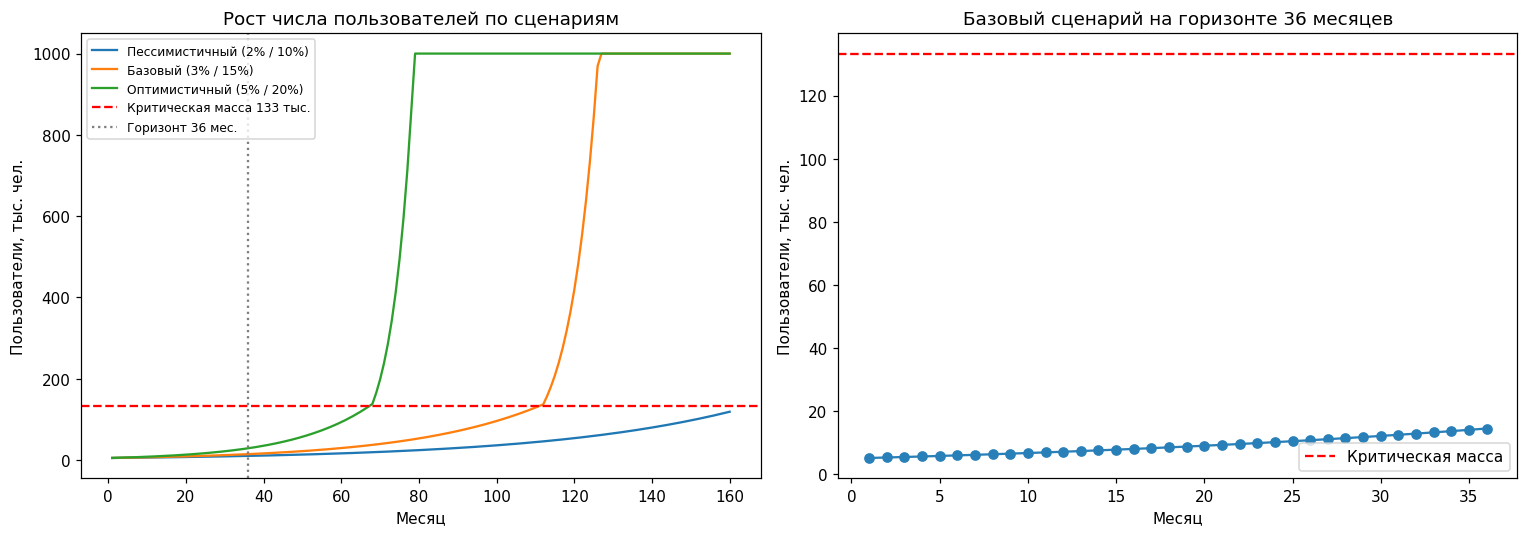

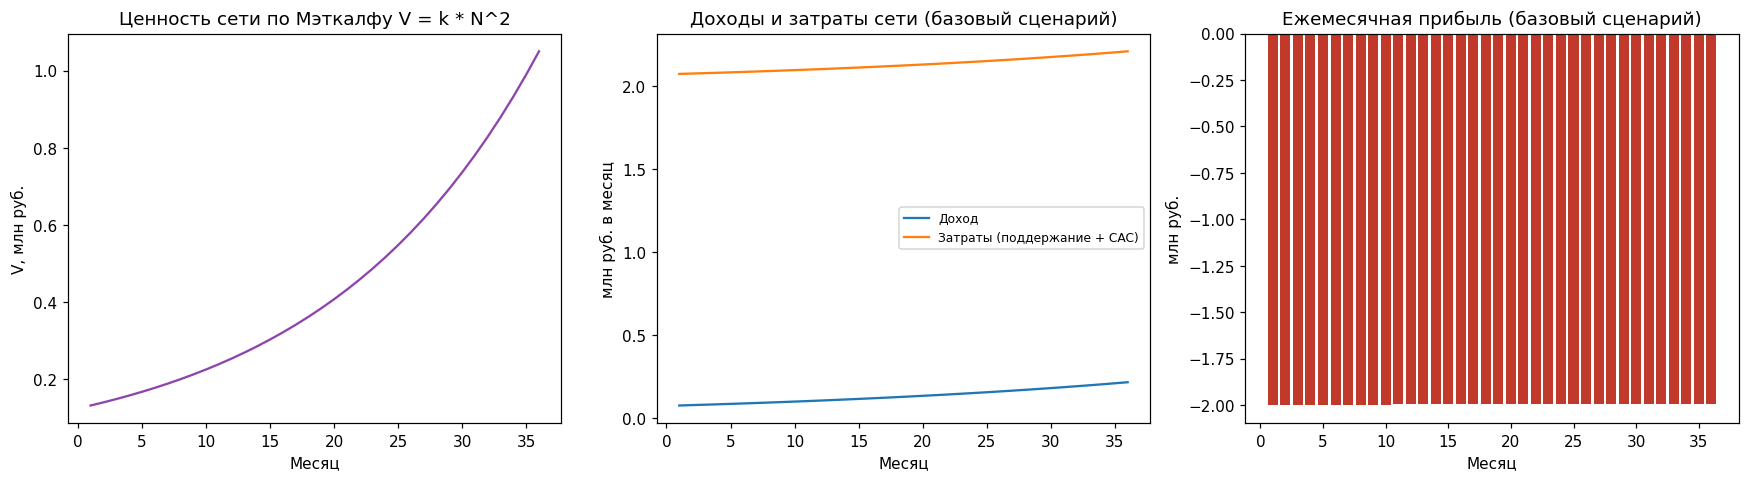

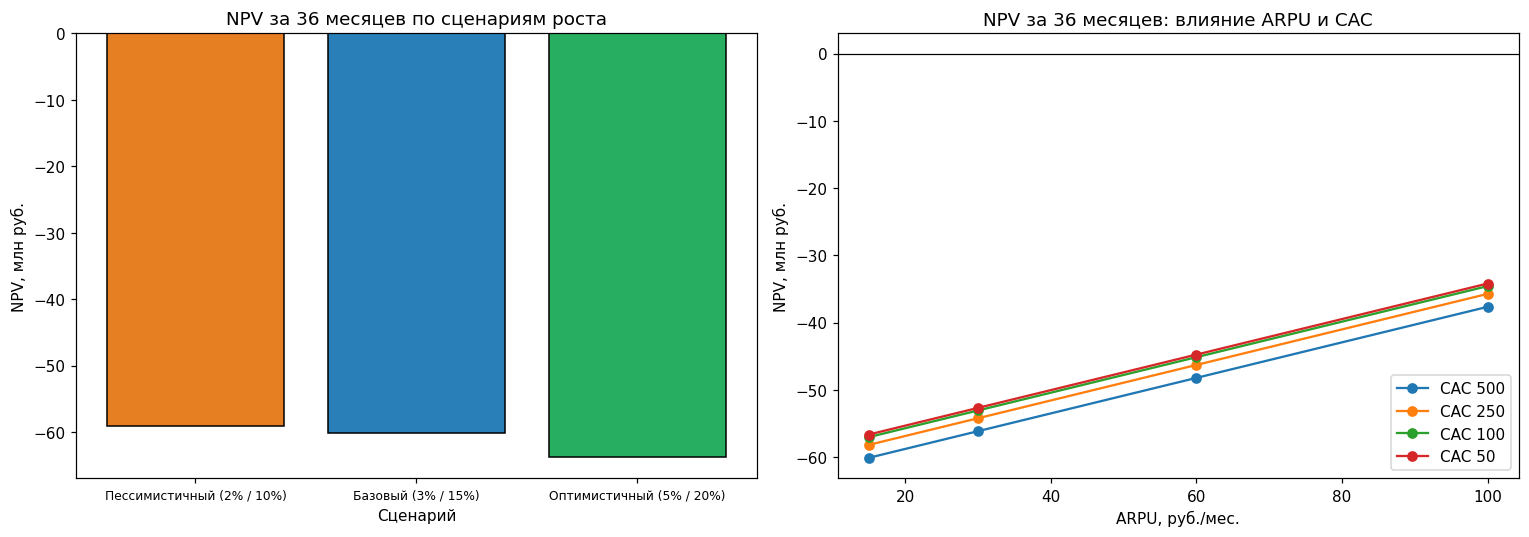

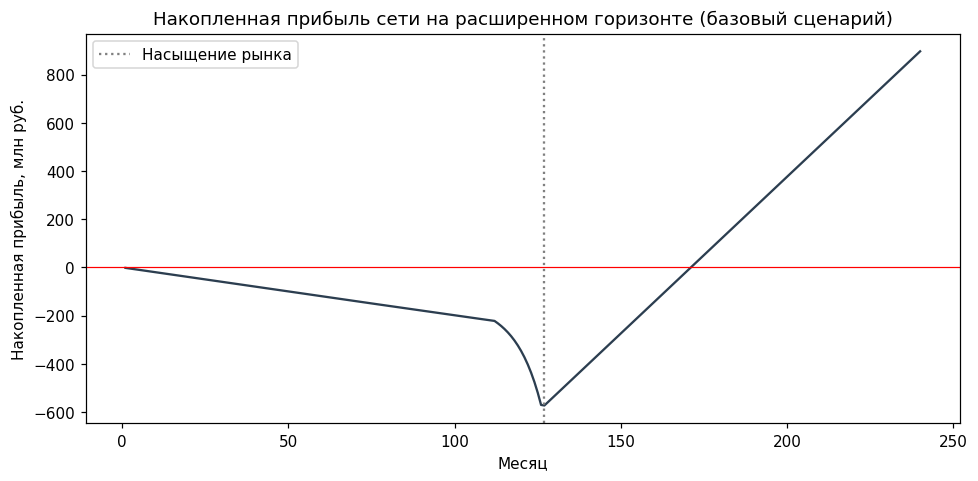

In [14]:
# 2.4. Визуализация результатов
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, (g1, g2) in scenarios.items():
    path = simulate(g1, g2, 160)
    axes[0].plot(path['Месяц'], path['Пользователи'] / 1e3, label=name)
axes[0].axhline(critical_mass / 1e3, color='red', linestyle='--',
                label=f'Критическая масса {critical_mass / 1e3:.0f} тыс.')
axes[0].axvline(horizon_months, color='gray', linestyle=':', label='Горизонт 36 мес.')
axes[0].set_title('Рост числа пользователей по сценариям')
axes[0].set_xlabel('Месяц')
axes[0].set_ylabel('Пользователи, тыс. чел.')
axes[0].legend(fontsize=8)

axes[1].plot(base['Месяц'], base['Пользователи'] / 1e3, 'o-', color='#2980b9')
axes[1].axhline(critical_mass / 1e3, color='red', linestyle='--', label='Критическая масса')
axes[1].set_title('Базовый сценарий на горизонте 36 месяцев')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Пользователи, тыс. чел.')
axes[1].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(base['Месяц'], base['Ценность сети V'] / 1e6, color='#8e44ad')
axes[0].set_title('Ценность сети по Мэткалфу V = k * N^2')
axes[0].set_xlabel('Месяц')
axes[0].set_ylabel('V, млн руб.')
axes[1].plot(base['Месяц'], base['Доход R'] / 1e6, label='Доход')
axes[1].plot(base['Месяц'], base['Затраты'] / 1e6, label='Затраты (поддержание + CAC)')
axes[1].set_title('Доходы и затраты сети (базовый сценарий)')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('млн руб. в месяц')
axes[1].legend(fontsize=8)
axes[2].bar(base['Месяц'], base['Прибыль'] / 1e6, color='#c0392b')
axes[2].set_title('Ежемесячная прибыль (базовый сценарий)')
axes[2].set_xlabel('Месяц')
axes[2].set_ylabel('млн руб.')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
names = list(scenario_table.index)
axes[0].bar(names, scenario_table['NPV за 36 мес., руб.'] / 1e6, color=['#e67e22', '#2980b9', '#27ae60'], edgecolor='black')
axes[0].set_title('NPV за 36 месяцев по сценариям роста')
axes[0].set_xlabel('Сценарий')
axes[0].set_ylabel('NPV, млн руб.')
axes[0].tick_params(axis='x', labelsize=8)
for cac_label, row in grid.iterrows():
    axes[1].plot(arpu_values, row.values, 'o-', label=cac_label)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('NPV за 36 месяцев: влияние ARPU и CAC')
axes[1].set_xlabel('ARPU, руб./мес.')
axes[1].set_ylabel('NPV, млн руб.')
axes[1].legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(long_run['Месяц'], long_run['Накопленная прибыль'] / 1e6, color='#2c3e50')
ax.axhline(0, color='red', linewidth=0.8)
ax.axvline(saturation_month, color='gray', linestyle=':', label='Насыщение рынка')
ax.set_title('Накопленная прибыль сети на расширенном горизонте (базовый сценарий)')
ax.set_xlabel('Месяц')
ax.set_ylabel('Накопленная прибыль, млн руб.')
ax.legend()
plt.tight_layout()
plt.show()

RESULTS = {'critical_mass': critical_mass, 'months_to_cr': months_to_cr, 'months_cr_to_market': months_cr_to_market,
           'npv_base': npv_base, 'users36': base['Пользователи'].iloc[-1], 'v_cr': k_network * critical_mass ** 2,
           'v_cr_user': k_network * critical_mass, 'g_max': max_sustainable_growth,
           'npv_pess': scenario_table['NPV за 36 мес., руб.'].iloc[0], 'npv_opt': scenario_table['NPV за 36 мес., руб.'].iloc[2],
           'users_pess': scenario_table['Пользователей через 36 мес.'].iloc[0], 'users_opt': scenario_table['Пользователей через 36 мес.'].iloc[2],
           'm_pess': scenario_table['Мес. до критической массы'].iloc[0], 'm_opt': scenario_table['Мес. до критической массы'].iloc[2],
           'arpu_be': arpu_break_even, 'needed_growth': needed_growth, 'extra_users': extra_users, 'extra_marketing': extra_marketing,
           'total_acq': total_acquisition, 'target_months': target_months, 'saturation_month': saturation_month, 'deepest': deepest,
           'payback_month': payback_month, 'npv240': long_run['Дисконтированный накопленный'].iloc[-1],
           'grid_100_30': grid.loc['CAC 100', 'ARPU 30'], 'grid_50_30': grid.loc['CAC 50', 'ARPU 30'], 'grid_100_15': grid.loc['CAC 100', 'ARPU 15'],
           'grid_50_15': grid.loc['CAC 50', 'ARPU 15'], 'lev': lever_table['NPV за 36 мес., млн руб.'].tolist(), 'lev_users': lever_table['Пользователей через 36 мес.'].tolist(), 'grid_500_100': grid.loc['CAC 500', 'ARPU 100']}

In [15]:
print('Готово')

Готово


## 3. АНАЛИЗ РЕЗУЛЬТАТОВ

### 3.1. Интерпретация полученных данных
- **Критическая масса** = затраты на поддержание / ARPU = 133 333 чел. (13,3% от потенциала рынка в 1 млн). Это нижняя граница: при такой базе доход лишь покрывает поддержание сети.
- **С учётом CAC** формула N = F / (ARPU − CAC·g) даёт ARPU − CAC·g = 15 − 500·0,03 = 0: при росте 3% в месяц весь доход пользователя уходит на привлечение новых, и прибыль сети постоянно равна «минус затраты на поддержание» (около −2 млн руб. в месяц, см. таблицу помесячных расчётов). Максимальный темп роста, который сеть способна профинансировать из дохода, — 3% в месяц. При росте 15% после критической массы каждый новый пользователь стоит 75 руб. в месяц против 15 руб. дохода — рост убыточен.
- **Срок достижения:** при росте 3% критическая масса достигается через 112 мес. (9,3 года), то есть далеко за пределами горизонта 36 мес.; к концу горизонта в сети будет 14 491 чел. Рост 15% после критической массы даёт насыщение рынка ещё через 15 мес.
- **Ценность сети по Мэткалфу** растёт квадратично: при критической массе V = 88,89 млн руб., то есть 667 руб. на пользователя, тогда как монетизируется только 15 руб. (около 2% созданной ценности). Это главный резерв проекта: сеть создаёт ценность, но платформа её не извлекает.
- **NPV за 36 месяцев = −60,10 млн руб.** — в горизонте проект не окупается: расходы на поддержание (72 млн руб. за 3 года) несоизмеримы с доходом базы в 5–14 тыс. человек (до 0,2 млн руб. в месяц).
- **Расширенный горизонт (справочно):** рынок насыщается на 127-м месяце, максимальный накопленный дефицит достигает 573 млн руб., накопленная прибыль становится положительной лишь на 172-м месяце (прибыль насыщенной сети 13 млн руб. в месяц), NPV за 20 лет 9,78 млн руб. Проект «выстреливает» только при исполнении сценария полного охвата города и при готовности финансировать почти 0,6 млрд руб. дефицита.

### 3.2. Сравнение с альтернативными вариантами
| Сценарий роста (до/после КМ) | Пользователей через 36 мес. | NPV за 36 мес., млн руб. | Мес. до критической массы |
|---|---|---|---|
| Пессимистичный (2% / 10%) | 10 199 | −59,09 | 166 |
| Базовый (3% / 15%) | 14 491 | −60,10 | 112 |
| Оптимистичный (5% / 20%) | 28 959 | −63,74 | 68 |

**Парадокс сценариев:** при CAC = 500 руб. ускорение роста **ухудшает** NPV за 36 месяцев (оптимистичный сценарий хуже базового). Причина: срок окупаемости привлечения одного пользователя равен CAC / ARPU = 33 месяца, то есть дольше горизонта. Каждый дополнительный пользователь, привлечённый «в долг», в горизонте приносит убыток. Темп роста сам по себе не создаёт стоимость, пока юнит-экономика привлечения не сходится.

**Безубыточный ARPU** за 36 месяцев при базовой траектории — около 197 руб. в месяц (в 13 раз выше текущих 15 руб.), а операционный ARPU безубыточности при стартовых 5 000 пользователей — 400 руб.

**Рычаги стратегии (NPV за 36 мес., млн руб.):** снижение CAC до 100 руб. и рост ARPU до 30 руб. дают лишь −53,06: узким местом остаются постоянные затраты 2 млн руб. в месяц. При сокращении постоянных затрат до 0,5 млн руб. NPV = −7,9 млн руб., а в комплексном сценарии (CAC 100, ARPU 30, затраты 0,5 млн руб., рост 8% до критической массы) NPV = 13,6 млн руб. при 280 354 пользователей.

## 4. ВЫВОДЫ И РЕКОМЕНДАЦИИ

### 4.1. Ключевые выводы
1. Критическая масса сети — 133 333 чел. Достичь её при росте 3% в месяц можно только через 112 мес.; в горизонте 36 мес. сеть вырастет лишь до 14 491 чел.
2. NPV за 36 месяцев отрицателен во всех сценариях роста (−59,09 / −60,10 / −63,74 млн руб.). Базовые параметры (CAC 500 руб., ARPU 15 руб.) делают платный рост убыточным: привлечение окупается за 33 мес.
3. Ценность сети по Мэткалфу растёт как N², а доход — линейно; монетизируется малая доля ценности. Проект имеет смысл только при смене модели монетизации и привлечения.
4. Чтобы приблизить критическую массу на 6 месяцев (с 112 до 106), нужен рост 3,15% в месяц вместо 3% и дополнительные инвестиции в привлечение около 9,30 млн руб. (≈ 18 593 чел. × 500 руб.), что составляет 14% общего бюджета привлечения до критической массы (64,17 млн руб.). По сути это опережающее финансирование и сдвиг расходов во времени, а не новая статья затрат.

### 4.2. Практические рекомендации
1. **Не масштабировать платное привлечение при CAC = 500 руб.** Сначала довести CAC до 100 руб. и ниже через реферальную программу, партнёрства с городскими сервисами, органику (тогда самофинансируемый рост достигает 15% в месяц).
2. **Снизить постоянные затраты** (2 млн руб. в месяц избыточны для сети с 5–15 тыс. пользователей): запускать по районам, использовать облачную инфраструктуру с оплатой по факту, отложить дорогие функции. Это самый сильный рычаг в расчётах.
3. **Повышать ARPU по мере роста сети**, используя квадратичный рост её ценности: локальная реклама, премиум-сервисы для бизнеса, платные объявления. Цель — не менее 30–60 руб. на пользователя.
4. **Этапный запуск:** район → несколько районов → город; переход к следующему этапу только при CAC-payback менее 12 мес.
5. **Контрольные точки (стоп-критерии):** доля пользователей, пришедших органически; удержание на 3-й месяц; ARPU; месяц выхода на покрытие поддержания. Если к 12-му месяцу CAC-payback остаётся выше 24 месяцев, проект нужно пересмотреть или остановить.
6. **Финансирование:** для реализации полного сценария до насыщения города нужен резерв около 573 млн руб. и инвестор с горизонтом более 10 лет; при отсутствии такого финансирования реалистичнее нишевой запуск.